In [35]:
import numpy as np
import pandas as pd
from sklearn.preprocessing import  StandardScaler
customers=pd.read_csv("Mall_Customers.csv")
print(customers.head())
print(customers.info())

features=['Age','Annual Income (k$)','Spending Score (1-100)']
X=customers[features]

scaler=StandardScaler()
X_scaled=scaler.fit_transform(X)
print(X_scaled[:5])

   CustomerID  Gender  Age  Annual Income (k$)  Spending Score (1-100)
0           1    Male   19                  15                      39
1           2    Male   21                  15                      81
2           3  Female   20                  16                       6
3           4  Female   23                  16                      77
4           5  Female   31                  17                      40
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   CustomerID              200 non-null    int64 
 1   Gender                  200 non-null    object
 2   Age                     200 non-null    int64 
 3   Annual Income (k$)      200 non-null    int64 
 4   Spending Score (1-100)  200 non-null    int64 
dtypes: int64(4), object(1)
memory usage: 7.9+ KB
None
[[-1.42456879 -1.73899919 -0.43480148]
 [-1.2810354

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(
c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Window

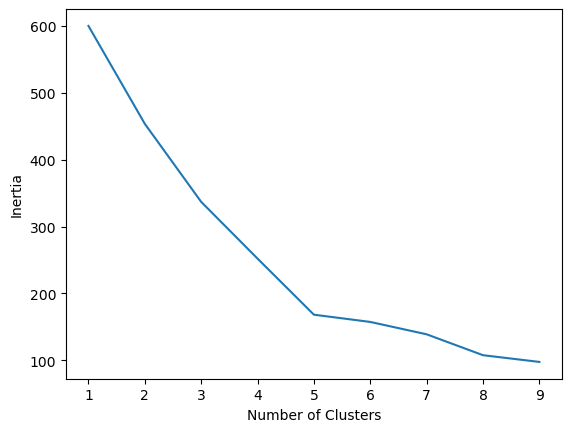

c:\ProgramData\anaconda3\Lib\site-packages\sklearn\cluster\_kmeans.py:1419: UserWarning: KMeans is known to have a memory leak on Windows with MKL, when there are less chunks than available threads. You can avoid it by setting the environment variable OMP_NUM_THREADS=1.
  warnings.warn(


Silhouette score: 0.41664341513732767


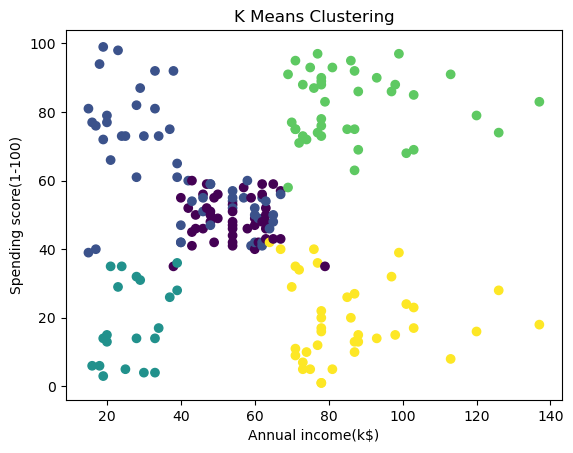

               Age  Annual Income (k$)  Spending Score (1-100)
Cluster                                                       
0        55.638298           54.382979               48.851064
1        25.185185           41.092593               62.240741
2        46.250000           26.750000               18.350000
3        32.875000           86.100000               81.525000
4        39.871795           86.102564               19.358974


C:\Users\shaha\AppData\Local\Temp\ipykernel_7296\3380148774.py:29: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['Cluster']= labels


In [30]:
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt
from sklearn.metrics import silhouette_score

inertia=[]
clusters=[]
for K in range(1,10):
    K_model=KMeans(n_clusters=K, random_state=1)
    K_model.fit(X_scaled)
    inertia.append(K_model.inertia_)
    clusters.append(K)
    
plt.plot(clusters, inertia)
plt.xlabel("Number of Clusters")
plt.ylabel("Inertia")
plt.show()

KMeansModel=KMeans(n_clusters=5, random_state=1, n_init=10)
labels=KMeansModel.fit_predict(X_scaled)
score=silhouette_score(X_scaled, labels)
print("Silhouette score:", score)

plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=labels)
plt.title("K Means Clustering")
plt.xlabel("Annual income(k$)")
plt.ylabel("Spending score(1-100)")
plt.show()

X['Cluster']= labels
cluster_summary=X.groupby('Cluster').mean()
print(cluster_summary)

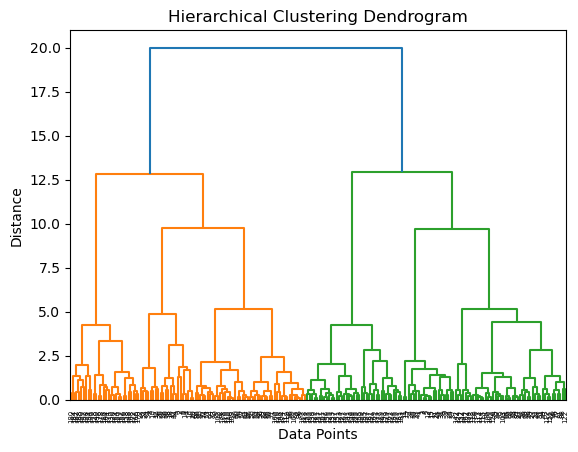

In [31]:
from scipy.cluster.hierarchy import linkage, dendrogram
import matplotlib.pyplot as plt

linked = linkage(X_scaled, method='ward')
dendrogram(linked)
plt.title('Hierarchical Clustering Dendrogram')
plt.xlabel('Data Points')
plt.ylabel('Distance')
plt.show()

Hierarchical Clustering Silhouette Score: 0.39002826186267214


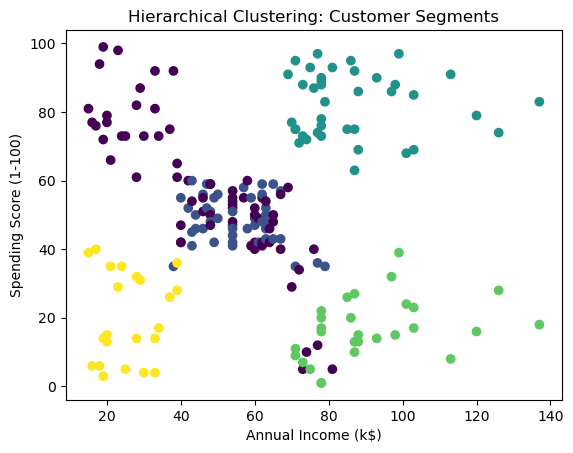

In [33]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hc = AgglomerativeClustering(n_clusters=5, linkage='ward')
hc_labels = hc.fit_predict(X_scaled)
hc_score = silhouette_score(X_scaled, hc_labels)
print("Hierarchical Clustering Silhouette Score:", hc_score)
plt.scatter(X['Annual Income (k$)'], X['Spending Score (1-100)'], c=hc_labels)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('Hierarchical Clustering: Customer Segments')
plt.show()

Number of clusters: 6
Number of noise points: 60


C:\Users\shaha\AppData\Local\Temp\ipykernel_7296\2424866992.py:6: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  X['DBSCAN_Cluster']=labels


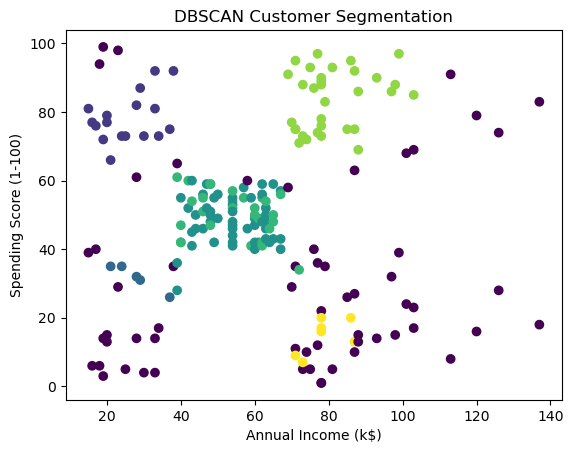

Silhouette Score: 0.481714917862304


In [40]:
from sklearn.cluster import DBSCAN


dbscan=DBSCAN(eps=0.5, min_samples=5)
labels=dbscan.fit_predict(X_scaled)
X['DBSCAN_Cluster']=labels

unique_labels=set(labels)
n_clusters=len(unique_labels-{-1}) #-1 represents noise
n_noise=np.sum(labels==-1)

print("Number of clusters:", n_clusters)
print("Number of noise points:", n_noise)

plt.scatter(
    X['Annual Income (k$)'],
    X['Spending Score (1-100)'],
    c=labels,
)
plt.xlabel('Annual Income (k$)')
plt.ylabel('Spending Score (1-100)')
plt.title('DBSCAN Customer Segmentation')
plt.show()

mask = labels != -1
valid_labels = labels[mask]

if len(set(valid_labels)) >= 2:
    score = silhouette_score(X_scaled[mask], valid_labels)
    print("Silhouette Score:", score)
else:
    print("Silhouette score is not applicable.")